# Checkpoint 4: One-Stage Anchor-Free Detector (YOLO26s)

Fine-tunes COCO-pretrained YOLO26s on VisDrone and evaluates it with the shared COCO protocol
(sequence-held-out validation split, every 3rd frame, ignored regions treated as "don't care").

Sections:
1. Setup
2. Configuration
3. Data
4. Training (resumes automatically from the last saved epoch)
5. Training curves
6. Validation metrics
7. Kaggle submission

## 1. Setup

Set `RUNTIME` to `"colab"` (checkpoints go to Google Drive) or `"local"` (checkpoints go to `runs/`).
On Colab, upload `kaggle.json` to the session first so the dataset can be downloaded.

In [1]:
RUNTIME = "local"  # "colab" or "local"
REPO_URL = "https://github.com/rudkoLA/ai-hw-2-rudko-omelianchuk.git"

In [2]:
import os
import subprocess
import sys
from pathlib import Path

if RUNTIME == "colab":
    repo_dir = Path("/content/ai-hw-2-rudko-omelianchuk")
    if not repo_dir.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir)
    uploaded_key = Path("/content/kaggle.json")
    if uploaded_key.exists():
        kaggle_key = Path.home() / ".kaggle" / "kaggle.json"
        kaggle_key.parent.mkdir(parents=True, exist_ok=True)
        kaggle_key.write_bytes(uploaded_key.read_bytes())
        kaggle_key.chmod(0o600)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics", "pycocotools", "kaggle"], check=True)

print(f"Working directory: {Path.cwd()}")

Working directory: c:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk


In [3]:
import pandas as pd
from ultralytics import YOLO

from src.yolo import make_yolo_trainer
from src.setup_utils import ensure_dataset, resolve_storage, setup_environment
from src.submission import submit_to_kaggle
from src.ultralytics_utils import (
    evaluate_run,
    plot_training_curves,
    predict_submission,
    train_or_resume,
    write_yolo_split,
)

env = setup_environment(seed=42, mount_gdrive=False)
dataset_dir, coco_train, coco_val, class_names = ensure_dataset()
storage = resolve_storage(RUNTIME, "cp4_yolo")

[Environment]: CUDA GPU (NVIDIA GeForce RTX 3070, 8.0 GB VRAM) -> Mixed Precision (AMP Enabled)
[Dataset]: Resolved dataset root at -> dataset
[Storage]: local -> C:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk\runs\cp4_yolo


## 2. Configuration

All tunable parameters. Every key that is not listed in `NOTEBOOK_KEYS` is passed to Ultralytics `train()`,
so any other Ultralytics argument can be added to `CFG` directly.
Give every experiment its own `run_name`: an existing run with the same name is resumed (or skipped if finished).

`QUICK_TEST = True` trains on every 15th frame for 10 epochs with images cached in RAM, for fast comparisons
between settings; its runs get a `_quick` suffix. Use `QUICK_TEST = False` for the final run.

In [12]:
CFG = {
    "run_name": "check4_3_nop2",
    "weights": "yolo26s.pt",      # COCO-pretrained
    "p2_head": False,              # True adds a stride-4 detection head (yolo26s-p2.yaml)
    "train_stride": 3,             # every n-th frame of each training sequence
    "val_stride": 3,               # every n-th frame of each validation sequence
    # Schedule
    "imgsz": 1024,
    "epochs": 20,
    "batch": 6,                   # -1: largest batch that fits in GPU memory
    "cache": "ram",                # "ram" caches resized images (needs ~2x their size in free RAM)
    "patience": 10,                # early stopping (epochs without val improvement)
    "close_mosaic": 10,            # last n epochs without mosaic augmentation
    "optimizer": "MuSGD",
    "lr0": 0.01,
    "momentum": 0.9,
    "weight_decay": 5e-4,
    "warmup_epochs": 3,
    "warmup_bias_lr": 0.0,
    # Loss weights (for YOLO26 "dfl" weights the L1 box-distance term)
    "box": 7.5,
    "cls": 0.5,
    "dfl": 1.5,
    # Label assignment and box regression loss
    "tal_topk": 10,                # positives per object (one-to-many branch)
    "stal_min_side": None,         # GT sides below this (px) are enlarged for assignment; None = default, 0 = off
    "iou_type": "CIoU",            # "CIoU", "DIoU", "GIoU" or "IoU"
    # Inference
    "max_det": 500,
    "nms_free": True,             # True: one-to-one head without NMS; False: one-to-many head + NMS
    "nms_iou": 0.7,                # NMS IoU threshold (used when nms_free is False)
    # Misc
    "workers": 4,
    "seed": 42,
}

QUICK_TEST = False
if QUICK_TEST:
    CFG.update({
        "run_name": CFG["run_name"] + "_quick",
        "train_stride": 15,
        "epochs": 10,
        "patience": 3,
        "close_mosaic": 3,
        "cache": "ram",
        "fraction": 0.1
    })

# Keys used by this notebook rather than by Ultralytics train()
NOTEBOOK_KEYS = {
    "run_name", "weights", "p2_head", "train_stride", "val_stride",
    "tal_topk", "stal_min_side", "iou_type", "max_det", "nms_free", "nms_iou",
}

## 3. Data

Writes Ultralytics image lists for every `train_stride`-th / `val_stride`-th frame of each sequence. The frame selection is
the same one used by `VisDroneDataset`, so all detectors are trained and evaluated on identical frames.

In [5]:
data_yaml, frames = write_yolo_split(
    dataset_dir,
    {"train": coco_train, "val": coco_val},
    out_dir=storage / "lists" / f"train{CFG['train_stride']}_val{CFG['val_stride']}",
    class_names=class_names,
    stride={"train": CFG["train_stride"], "val": CFG["val_stride"]},
)
del coco_train  # large; only the selected frames are needed from here on

[train]: 8,090 frames (stride=3) -> C:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk\runs\cp4_yolo\lists\train3_val3\train.txt
[val]: 951 frames (stride=3) -> C:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk\runs\cp4_yolo\lists\train3_val3\val.txt


## 4. Training

Checkpoints (`last.pt` every epoch, `best.pt`) and `results.csv` are written to `storage/<run_name>`.
Re-running this cell after an interruption resumes from `last.pt`; a finished run is not retrained.

In [8]:
Trainer = make_yolo_trainer(
    tal_topk=CFG["tal_topk"],
    stal_min_side=CFG["stal_min_side"],
    iou_type=CFG["iou_type"],
)
run_dir = storage / CFG["run_name"]

train_or_resume(
    YOLO,
    "yolo26s-p2.yaml" if CFG["p2_head"] else "yolo26s.yaml",
    Trainer,
    run_dir,
    train_args={
        "data": str(data_yaml),
        "pretrained": CFG["weights"],
        **{k: v for k, v in CFG.items() if k not in NOTEBOOK_KEYS},
    },
    config=CFG,
)

Run 'check4_3_nop2': resume
Ultralytics 8.4.208  Python-3.12.10 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3070, 8191MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk\runs\cp4_yolo\lists\train3_val3\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\Users\Dog\Desktop\ai-h

KeyboardInterrupt: 

## 5. Training curves

Per-epoch validation mAP and losses logged by Ultralytics. These per-epoch metrics use Ultralytics' own
evaluator; the final numbers in Section 6 come from the shared COCO evaluation.

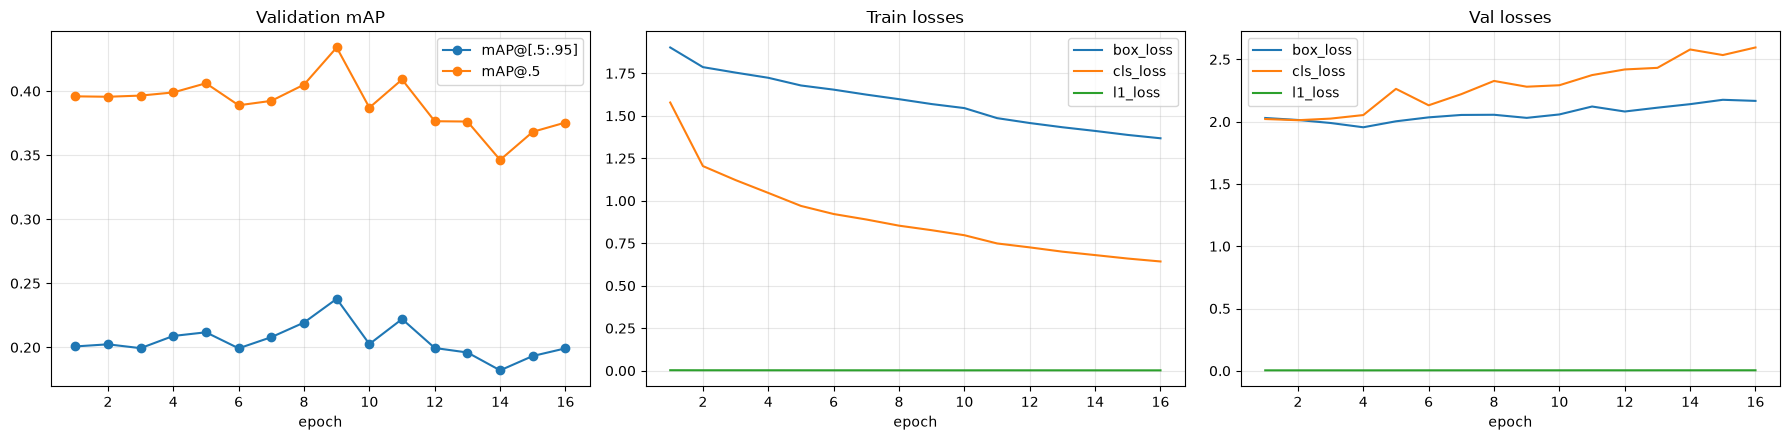

In [9]:
history = plot_training_curves(run_dir)

## 6. Validation metrics

`best.pt` is evaluated on the validation frames with `evaluate_coco_metrics` (up to 500 detections per image;
with `nms_free=True` YOLO26 predicts with its one-to-one head and skips NMS). Results are saved to `storage/<run_name>/metrics.json`.

In [13]:
PREDICT_KWARGS = {"nms": False} if CFG["nms_free"] else {"iou": CFG["nms_iou"]}

best_model = YOLO(str(run_dir / "weights" / "best.pt"))
metrics = evaluate_run(
    best_model,
    frames["val"],
    dataset_dir,
    imgsz=CFG["imgsz"],
    max_det=CFG["max_det"],
    batch=CFG["batch"],
    run_dir=run_dir,
    predict_kwargs=PREDICT_KWARGS,
)
pd.Series(metrics, name=CFG["run_name"]).round(4).to_frame()

loading annotations into memory...
Done (t=0.28s)
creating index...
index created!
Loading and preparing results...
DONE (t=1.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=57.67s).
Accumulating evaluation results...
DONE (t=1.66s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=500 ] = 0.376
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=500 ] = 0.191
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.087
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.215
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.326
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.120
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.286
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDe

,check4_3_nop2
mAP_50_95,0.2006
mAP_50,0.3762
mAP_75,0.1911
mAP_small,0.0869
mAP_medium,0.2153
mAP_large,0.3259
mAR,0.3999
mAR_small,0.2180
mAR_medium,0.4002
mAR_large,0.5605


## 7. Kaggle submission

Predicts all test frames with `best.pt` and writes `storage/<run_name>/submission.csv`
(boxes in original pixel coordinates, at most 500 detections per image, empty rows for frames without detections).

In [14]:
submission_path = run_dir / "submission.csv"
report = predict_submission(
    best_model,
    dataset_dir,
    submission_path,
    imgsz=CFG["imgsz"],
    max_det=CFG["max_det"],
    batch=CFG["batch"],
    predict_kwargs=PREDICT_KWARGS,
)
report

{'is_valid': True,
 'errors': [],
 'rows': 3811,
 'expected_rows': 3811,
 'empty_rows': 0,
 'detections': 1365568,
 'size_MB': 42.52}

Set `SUBMIT = True` to upload the file (requires `~/.kaggle/kaggle.json`).

In [15]:
SUBMIT = True
SUBMISSION_MESSAGE = f"CP4 YOLO26s {CFG['run_name']}"
os.environ["KAGGLE_API_TOKEN"] = "KGAT_b939dc7b9ae093e004837dc162651189"

if SUBMIT:
    assert report["is_valid"], report["errors"]
    submit_to_kaggle(submission_path, SUBMISSION_MESSAGE)

Submission ref: 58177723
4 submissions remaining today.
Successfully submitted to Multiple Object Video Detection | HW2 | UCU AI 2026
0%|          | 0.00/40.5M [00:00<?, ?B/s]
  0%|          | 16.0k/40.5M [00:00<09:56, 71.3kB/s]
  1%|в–Џ         | 544k/40.5M [00:00<00:32, 1.28MB/s] 
  2%|в–Џ         | 672k/40.5M [00:00<00:47, 879kB/s] 
  2%|в–Џ         | 768k/40.5M [00:00<00:51, 813kB/s]
 24%|в–€в–€в–Ќ       | 9.81M/40.5M [00:01<00:02, 15.9MB/s]
 28%|в–€в–€в–Љ       | 11.3M/40.5M [00:01<00:02, 14.2MB/s]
 31%|в–€в–€в–€в–Џ      | 12.7M/40.5M [00:01<00:02, 13.8MB/s]
 38%|в–€в–€в–€в–Љ      | 15.4M/40.5M [00:01<00:01, 16.9MB/s]
 45%|в–€в–€в–€в–€в–Њ     | 18.4M/40.5M [00:01<00:01, 20.2MB/s]
 53%|в–€в–€в–€в–€в–€в–Ћ    | 21.5M/40.5M [00:01<00:00, 23.0MB/s]
 62%|в–€в–€в–€в–€в–€в–€в–Џ   | 25.0M/40.5M [00:01<00:00, 26.8MB/s]
 71%|в–€в–€в–€в–€в–€в–€в–€   | 28.7M/40.5M [00:01<00:00, 29.7MB/s]
 79%|в–€в–€в–€в–€в–€в–€в–€в–‰  | 32.0M/40.5M [00:02<00:00, 31.0MB/s]
 87%|в–€в–€в–€в–€в–€в–€в–€в–€в–‹ | 35.